In [34]:
import pandas as pd
import numpy as np
import pyarrow.feather as feather
import os
import seaborn as sns
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context("notebook", font_scale=1.2)
colors = sns.color_palette("muted")

In [35]:
DATA_DIR = "../data/sweep_2026_03_03_1547" 

print(f"Loading data from {DATA_DIR}...")
df_sims = feather.read_feather(os.path.join(DATA_DIR, "simulations.arrow"))
df_nodes = feather.read_feather(os.path.join(DATA_DIR, "nodes.arrow"))
df_cascades = feather.read_feather(os.path.join(DATA_DIR, "cascades.arrow"))

print(f"Loaded {len(df_sims)} simulation runs.")
print(f"Loaded {len(df_nodes)} agent records.")

Loading data from ../data/sweep_2026_03_03_1547...
Loaded 25000 simulation runs.
Loaded 6250000 agent records.


In [36]:
# Aggregate simulations over the 30 topological repetitions
# This reduces our dataset to exactly 500 LHS points
df_lhs = df_sims.groupby('lhs_id').agg({
    'cost': 'first',
    'rep_loss': 'first',
    'verif_tpr': 'first',
    'verif_fpr': 'first',
    'fake_prob': 'first',
    'num_conn': 'first',
    'avg_welfare': 'mean',
    'avg_fake_cascade': 'mean',
    'avg_true_cascade': 'mean',
    'veracity_differential': 'mean',
    'avg_verify_rate': 'mean'
}).reset_index()

print(f"Aggregated down to {len(df_lhs)} unique LHS parameter combinations.")

Aggregated down to 500 unique LHS parameter combinations.


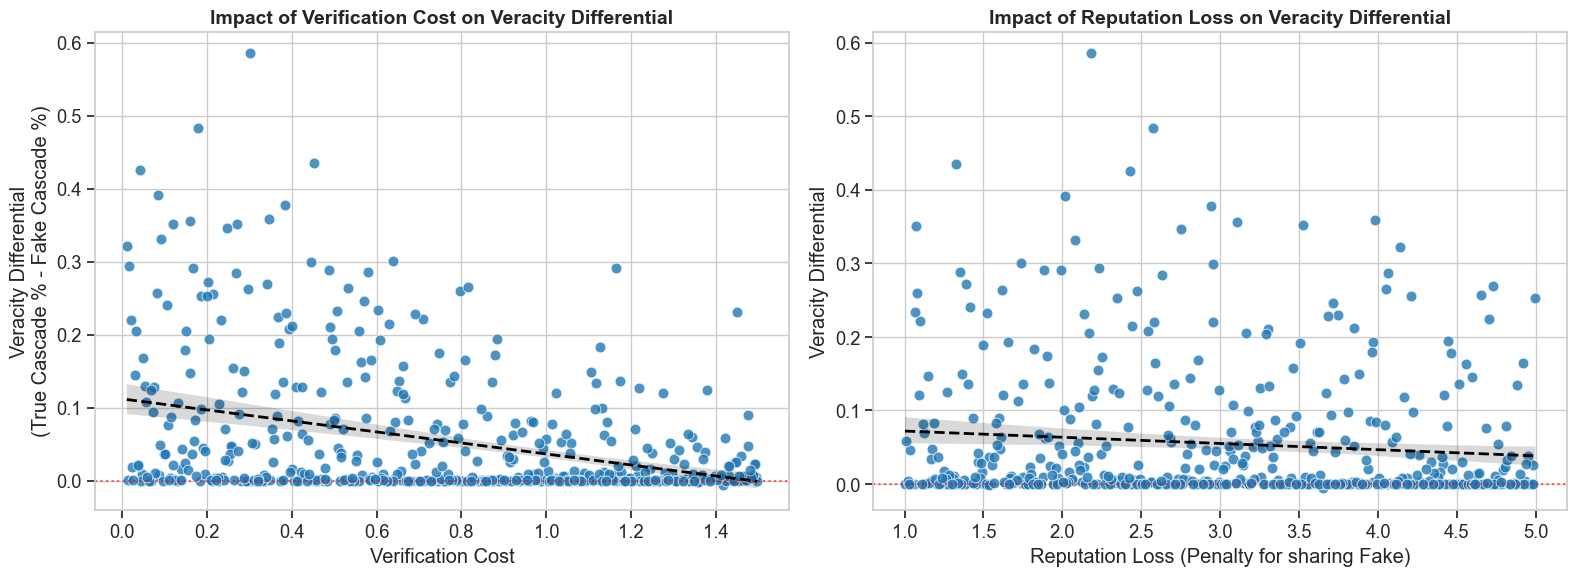

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Verification Cost vs Veracity Differential
sns.scatterplot(
    data=df_lhs, 
    x='cost', 
    y='veracity_differential', 
    alpha=0.8, 
    s=60, 
    ax=axes[0]
)
# Add a lowess smoothing line to see the trend
sns.regplot(
    data=df_lhs, x='cost', y='veracity_differential', 
    scatter=False, color='black', ax=axes[0], line_kws={'linewidth': 2, 'linestyle': '--'}
)
axes[0].set_title("Impact of Verification Cost on Veracity Differential", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Verification Cost")
axes[0].set_ylabel("Veracity Differential\n(True Cascade % - Fake Cascade %)")
axes[0].axhline(0, color='red', linestyle=':', alpha=0.6)

# Plot 2: Reputation Loss vs Veracity Differential
sns.scatterplot(
    data=df_lhs,
    x='rep_loss',
    y='veracity_differential', 
    alpha=0.8,
    s=60,
    ax=axes[1]
)
sns.regplot(
    data=df_lhs, x='rep_loss', y='veracity_differential', 
    scatter=False, color='black', ax=axes[1], line_kws={'linewidth': 2, 'linestyle': '--'}
)
axes[1].set_title("Impact of Reputation Loss on Veracity Differential", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Reputation Loss (Penalty for sharing Fake)")
axes[1].set_ylabel("Veracity Differential")
axes[1].axhline(0, color='red', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

/var/folders/mz/n_rzzjx149d19ncnxglpf7n40000gn/T/ipykernel_21848/3040999607.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes.legend()


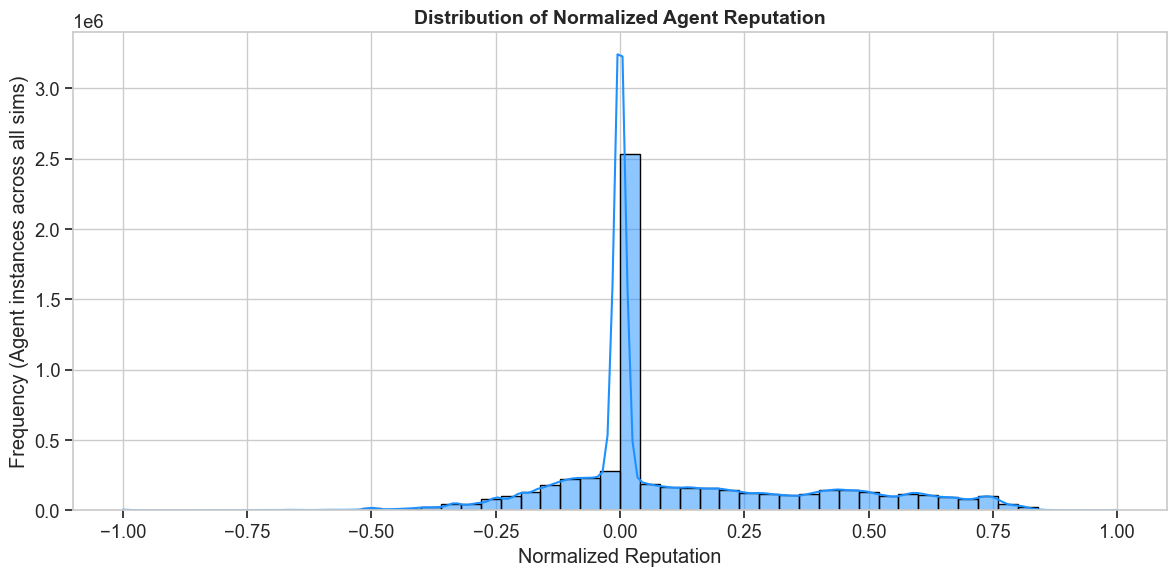

In [39]:
conditions = [
    (df_nodes["reputation"] > 0) & (df_nodes["best_reputation"] > 0),
    (df_nodes["reputation"] < 0) & (df_nodes["worst_reputation"] < 0),
    (df_nodes["reputation"] == 0)
]

choices = [
    df_nodes["reputation"] / df_nodes["best_reputation"],    # Yields [0, 1]
    -(df_nodes["reputation"] / df_nodes["worst_reputation"]), # Yields [-1, 0]
    0.0
]

df_nodes["normalized_efficiency"] = np.select(conditions, choices, default=np.nan)

valid_nodes = df_nodes.dropna(subset=["normalized_efficiency"]).copy()

fig, axes = plt.subplots(1, 1, figsize=(12, 6))

# 1. Overall Distribution of Reputation Efficiency
sns.histplot(valid_nodes['normalized_efficiency'], bins=50, kde=True, color='dodgerblue', ax=axes)
axes.set_title("Distribution of Normalized Agent Reputation", fontsize=14, fontweight='bold')
axes.set_xlabel("Normalized Reputation")
axes.set_ylabel("Frequency (Agent instances across all sims)")
axes.legend()

plt.tight_layout()
plt.show()

In [40]:
# 1. Map the 'lhs_id' from the simulations dataframe to the nodes dataframe
sim_to_lhs_map = df_sims.set_index('global_sim_id')['lhs_id'].to_dict()
valid_nodes['lhs_id'] = valid_nodes['global_sim_id'].map(sim_to_lhs_map)

# 2. Calculate the mean normalized efficiency for each LHS point
agent_efficiency_agg = valid_nodes.groupby('lhs_id')['normalized_efficiency'].mean().reset_index()
agent_efficiency_agg.rename(columns={'normalized_efficiency': 'avg_agent_efficiency'}, inplace=True)

# 3. Merge this back into our df_lhs dataframe
df_lhs = df_lhs.merge(agent_efficiency_agg, on='lhs_id', how='left')

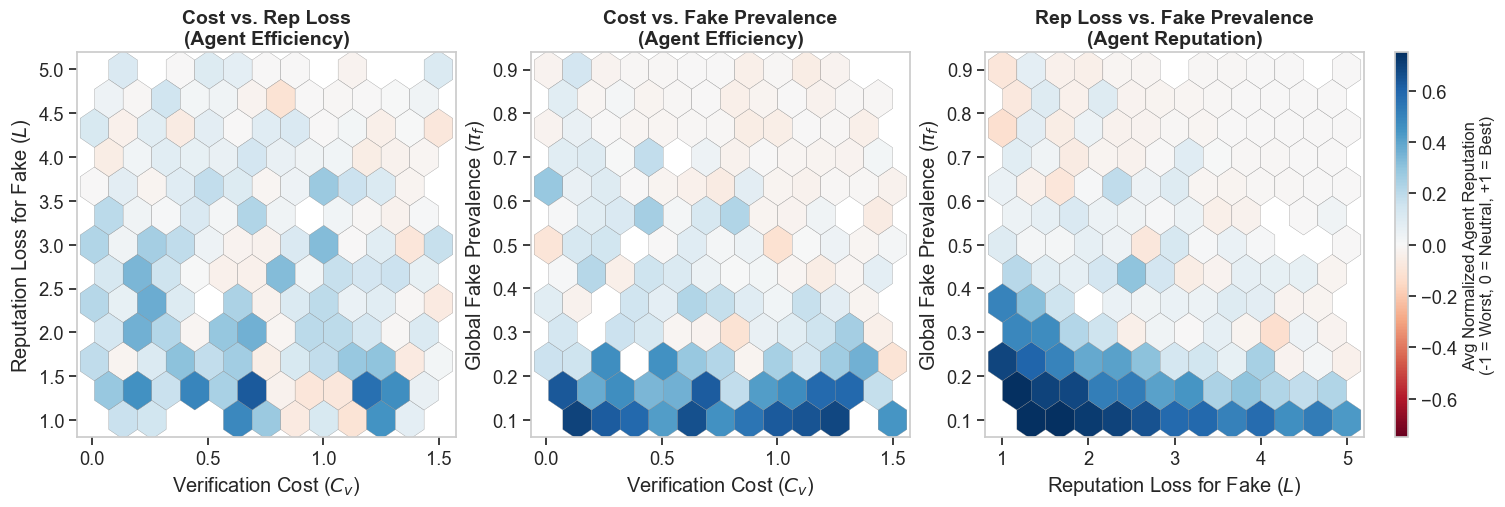

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Common visual settings for diverging metrics
cmap = 'RdBu'
vmin, vmax = -0.75, 0.75

# Plot 1: Cost vs. Rep Loss
hb1 = axes[0].hexbin(
    df_lhs['cost'],
    df_lhs['rep_loss'],
    C=df_lhs['avg_agent_efficiency'], 
    gridsize=12,
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    edgecolors='gray',
    linewidths=0.2
)
axes[0].set_title("Cost vs. Rep Loss\n(Agent Efficiency)", fontsize=14, fontweight='bold')
axes[0].set_xlabel(r"Verification Cost ($C_v$)")
axes[0].set_ylabel(r"Reputation Loss for Fake ($L$)")
axes[0].grid()

# Plot 2: Cost vs. Fake Prob
hb2 = axes[1].hexbin(
    df_lhs['cost'],
    df_lhs['fake_prob'],
    C=df_lhs['avg_agent_efficiency'], 
    gridsize=12,
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    edgecolors='gray',
    linewidths=0.2
)
axes[1].set_title("Cost vs. Fake Prevalence\n(Agent Efficiency)", fontsize=14, fontweight='bold')
axes[1].set_xlabel(r"Verification Cost ($C_v$)")
axes[1].set_ylabel(r"Global Fake Prevalence ($\pi_f$)")
axes[1].grid()

# Plot 3: Rep Loss vs. Fake Prob
hb3 = axes[2].hexbin(
    df_lhs['rep_loss'],
    df_lhs['fake_prob'],
    C=df_lhs['avg_agent_efficiency'], 
    gridsize=12,
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    edgecolors='gray',
    linewidths=0.2
)
axes[2].set_title("Rep Loss vs. Fake Prevalence\n(Agent Reputation)", fontsize=14, fontweight='bold')
axes[2].set_xlabel(r"Reputation Loss for Fake ($L$)")
axes[2].set_ylabel(r"Global Fake Prevalence ($\pi_f$)")
axes[2].grid()

# Add a single colorbar for the whole figure
cb = fig.colorbar(hb3, ax=axes.ravel().tolist(), pad=0.02, aspect=30)
cb.set_label('Avg Normalized Agent Reputation\n(-1 = Worst, 0 = Neutral, +1 = Best)', fontsize=12)

plt.show()

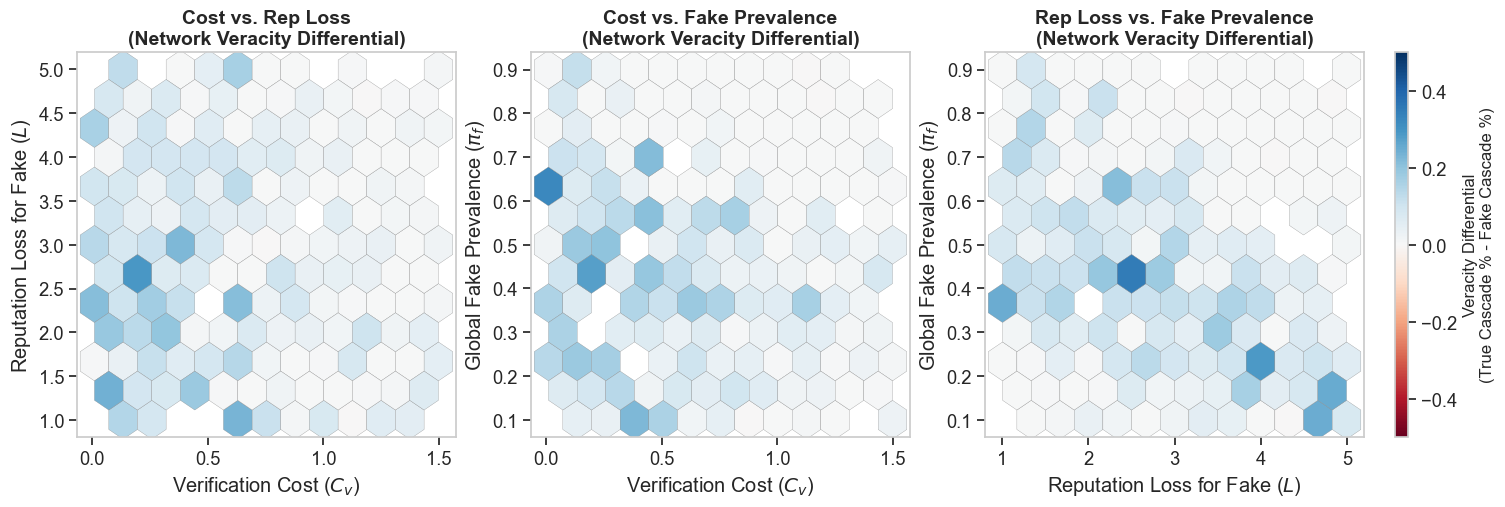

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

vmin_net, vmax_net = -0.5, 0.5

# Plot 1: Cost vs. Rep Loss
hb1 = axes[0].hexbin(
    df_lhs['cost'],
    df_lhs['rep_loss'],
    C=df_lhs['veracity_differential'], 
    gridsize=12,
    cmap=cmap,
    vmin=vmin_net,
    vmax=vmax_net,
    edgecolors='gray',
    linewidths=0.2
)
axes[0].set_title("Cost vs. Rep Loss\n(Network Veracity Differential)", fontsize=14, fontweight='bold')
axes[0].set_xlabel(r"Verification Cost ($C_v$)")
axes[0].set_ylabel(r"Reputation Loss for Fake ($L$)")
axes[0].grid()

# Plot 2: Cost vs. Fake Prob
hb2 = axes[1].hexbin(
    df_lhs['cost'],
    df_lhs['fake_prob'],
    C=df_lhs['veracity_differential'],
    gridsize=12,
    cmap=cmap,
    vmin=vmin_net,
    vmax=vmax_net,
    edgecolors='gray',
    linewidths=0.2
)

axes[1].set_title("Cost vs. Fake Prevalence\n(Network Veracity Differential)", fontsize=14, fontweight='bold')
axes[1].set_xlabel(r"Verification Cost ($C_v$)")
axes[1].set_ylabel(r"Global Fake Prevalence ($\pi_f$)")
axes[1].grid()

# Plot 3: Rep Loss vs. Fake Prob
hb3 = axes[2].hexbin(
    df_lhs['rep_loss'],
    df_lhs['fake_prob'],
    C=df_lhs['veracity_differential'], 
    gridsize=12,
    cmap=cmap,
    vmin=vmin_net, 
    vmax=vmax_net,
    edgecolors='gray',
    linewidths=0.2
)
axes[2].set_title("Rep Loss vs. Fake Prevalence\n(Network Veracity Differential)", fontsize=14, fontweight='bold')
axes[2].set_xlabel(r"Reputation Loss for Fake ($L$)")
axes[2].set_ylabel(r"Global Fake Prevalence ($\pi_f$)")
axes[2].grid()

cb = fig.colorbar(hb3, ax=axes.ravel().tolist(), pad=0.02, aspect=30)
cb.set_label('Veracity Differential\n(True Cascade % - Fake Cascade %)', fontsize=12)

plt.show()